# **Retail Store Sales: Dirty for Data Cleaning**

## **Dirty Retail Store Sales Dataset**

**Autor:** John Jairo Prado  
**Fuente:** [Kaggle — Retail Store Sales: Dirty for Data Cleaning](https://www.kaggle.com/datasets/ahmedmohamed2003/retail-store-sales-dirty-for-data-cleaning/)

---

## **Descripción del proyecto**

El conjunto de datos **Dirty Retail Store Sales** contiene **12.575 registros de datos sintéticos** que representan transacciones de venta de una tienda minorista.

La base contiene **8 categorías de productos**, con **25 artículos por categoría** y precios unitarios definidos. El dataset fue diseñado para simular problemas habituales de calidad de datos, incluyendo **valores faltantes e inconsistencias**, y permite desarrollar un flujo práctico de:

- Auditoría y calidad de datos.
- Limpieza y recuperación de información.
- Imputación estadística.
- Análisis exploratorio de datos (EDA).
- Ingeniería de características (*Feature Engineering*).

El objetivo de este proyecto es construir un proceso **reproducible, trazable y validable** para transformar los datos originales en un conjunto preparado para análisis.

---

**Última actualización:** se genera automáticamente al ejecutar el notebook.

# **0. Configuración de Rutas**

In [1]:
# 0. CONFIGURACIÓN DE RUTAS
# ------------------------------------------------------------

from pathlib import Path  # Gestiona rutas de forma portable

RUTA_PROYECTO = Path(".")  # Define como raíz la carpeta actual del proyecto
RUTA_RAW = RUTA_PROYECTO / "data" / "raw" / "retail_store_sales.csv"  # Define la ubicación del dataset original
RUTA_PROCESSED = RUTA_PROYECTO / "data" / "processed"  # Define la carpeta de datos procesados
RUTA_REPORTS = RUTA_PROYECTO / "data" / "reports"  # Define la carpeta de reportes
RUTA_FIGURES = RUTA_PROYECTO / "outputs" / "figures"  # Define la carpeta de gráficos

RUTA_PROCESSED.mkdir(parents=True, exist_ok=True)  # Crea la carpeta processed si no existe
RUTA_REPORTS.mkdir(parents=True, exist_ok=True)  # Crea la carpeta reports si no existe
RUTA_FIGURES.mkdir(parents=True, exist_ok=True)  # Crea la carpeta figures si no existe

## **0.1. Importar Dependencias**

In [2]:
# 0.1. Importar Dependencias
# ------------------------------------------------------------
import pandas as pd  # Importa pandas para manipulación de datos
import numpy as np  # Importa numpy para operaciones numéricas
import matplotlib.pyplot as plt  # Importa matplotlib para visualización

# **1. Ingesta**


In [3]:
# 01. Ingesta
# ------------------------------------------------------------
df_raw = pd.read_csv(RUTA_RAW)  # Carga el dataset original cuando el archivo esté disponible
df = df_raw.copy(deep=True)  # Crea una copia de trabajo y preserva el RAW

print(f"Ruta RAW esperada: {RUTA_RAW}")  # Confirma la ubicación esperada del dataset


Ruta RAW esperada: data\raw\retail_store_sales.csv


# **2. Inspección estructural**


In [4]:
# 2. Inspección estructural
# ------------------------------------------------------------
def glimpse_python(dataframe):
    """Genera un resumen estructural equivalente conceptualmente a glimpse() de Tidyverse."""
    resumen = pd.DataFrame({
        "variable": dataframe.columns,
        "dtype": dataframe.dtypes.astype(str).values,
        "n_missing": dataframe.isna().sum().values,
        "pct_missing": (dataframe.isna().mean().values * 100).round(2),
        "n_unique": dataframe.nunique(dropna=True).values
    })  # Construye el resumen estructural
    return resumen  # Devuelve el reporte

print(f"Filas: {df.shape[0]:,}")  # Reporta el número de observaciones
print(f"Columnas: {df.shape[1]:,}")  # Reporta el número de variables
print(df.columns.tolist())  # Presenta los nombres de las columnas
df.info()  # Muestra tipos físicos y valores no nulos
glimpse_python(df)  # Presenta el equivalente conceptual de glimpse()

Filas: 12,575
Columnas: 11
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.9+ MB


,variable,dtype,n_missing,pct_missing,n_unique
0,Transaction ID,str,0,0.00,12575
1,Customer ID,str,0,0.00,25
2,Category,str,0,0.00,8
3,Item,str,1213,9.65,200
4,Price Per Unit,float64,609,4.84,25
5,Quantity,float64,604,4.80,10
6,Total Spent,float64,604,4.80,227
7,Payment Method,str,0,0.00,3
8,Location,str,0,0.00,2
9,Transaction Date,str,0,0.00,1114


## **2.1. glimpse homologado de Tidyverse**

In [5]:
# 2.1. glimpse homologado de Tidyverse
# ------------------------------------------------------------
def glimpse_python(dataframe, n_values=5):
    """Muestra una vista estructural del DataFrame similar a dplyr::glimpse()."""

    mapa_tipos = {
        "object": "<chr>",
        "string": "<chr>",
        "str": "<chr>",
        "int64": "<int>",
        "Int64": "<int>",
        "int32": "<int>",
        "float64": "<dbl>",
        "float32": "<dbl>",
        "bool": "<lgl>",
        "boolean": "<lgl>",
        "datetime64[ns]": "<date>",
        "category": "<fct>"
    }  # Homologa tipos de pandas con etiquetas habituales de R/Tidyverse

    print(f"Rows: {dataframe.shape[0]:,}")  # Muestra el número de filas
    print(f"Columns: {dataframe.shape[1]:,}")  # Muestra el número de columnas

    ancho_variable = max(len(str(columna)) for columna in dataframe.columns)  # Calcula el ancho necesario para alinear nombres

    for columna in dataframe.columns:
        tipo_python = str(dataframe[columna].dtype)  # Obtiene el tipo de dato de pandas
        tipo_r = mapa_tipos.get(tipo_python, f"<{tipo_python}>")  # Obtiene el tipo equivalente de R

        valores = dataframe[columna].head(n_values).tolist()  # Obtiene los primeros valores de la variable

        valores_formateados = []
        for valor in valores:
            if pd.isna(valor):
                valores_formateados.append("NA")  # Representa faltantes como en R
            elif isinstance(valor, str):
                valores_formateados.append(f'"{valor}"')  # Coloca comillas en variables de texto
            else:
                valores_formateados.append(str(valor))  # Convierte valores numéricos a texto

        muestra = ", ".join(valores_formateados)  # Une los valores de ejemplo

        print(f"$ {columna:<{ancho_variable}} {tipo_r:<7} {muestra}, ...")  # Imprime cada variable al estilo glimpse

glimpse_python(df)

Rows: 12,575
Columns: 11
$ Transaction ID   <chr>   "TXN_6867343", "TXN_3731986", "TXN_9303719", "TXN_9458126", "TXN_4575373", ...
$ Customer ID      <chr>   "CUST_09", "CUST_22", "CUST_02", "CUST_06", "CUST_05", ...
$ Category         <chr>   "Patisserie", "Milk Products", "Butchers", "Beverages", "Food", ...
$ Item             <chr>   "Item_10_PAT", "Item_17_MILK", "Item_12_BUT", "Item_16_BEV", "Item_6_FOOD", ...
$ Price Per Unit   <dbl>   18.5, 29.0, 21.5, 27.5, 12.5, ...
$ Quantity         <dbl>   10.0, 9.0, 2.0, 9.0, 7.0, ...
$ Total Spent      <dbl>   185.0, 261.0, 43.0, 247.5, 87.5, ...
$ Payment Method   <chr>   "Digital Wallet", "Digital Wallet", "Credit Card", "Credit Card", "Digital Wallet", ...
$ Location         <chr>   "Online", "Online", "Online", "Online", "Online", ...
$ Transaction Date <chr>   "2024-04-08", "2023-07-23", "2022-10-05", "2022-05-07", "2022-10-02", ...
$ Discount Applied <chr>   True, True, False, NA, False, ...


**Inspección**

El dataset contiene **12.575 transacciones y 11 variables**.
The dataset contains **12,575 transactions and 11 variables**.

Las variables conservan sus nombres originales en inglés para mantener la trazabilidad con la fuente:
The variables retain their original English names to maintain traceability with the source:

- `Transaction ID`: identificador de la transacción. transaction identifier. 
- `Customer ID`: identificador del cliente. customer identifier.
- `Category`: categoría del producto. product category.
- `Item`: producto. product
- `Price Per Unit`: precio por unidad. price per unit.
- `Quantity`: cantidad comprada. quantity purchased. total expenditure.
- `Total Spent`: gasto total. payment method. payment method.
- `Payment Method`: método de pago. 
- `Location`: canal o ubicación de la compra. purchase channel or location.
- `Transaction Date`: fecha de la transacción. transaction date.
- `Discount Applied`: indica la aplicación de descuento. Indicates whether a discount was applied.

---

**Conclusions / Conclusiones**

**English**

The structural inspection shows that the dataset contains 12,575 transactions and 11 variables. The data combine transaction identifiers, customer and product information, purchase values, payment and sales-channel information, transaction dates, and a discount indicator.

Transaction ID, Customer ID, Category, Item, Payment Method, Location, and Transaction Date are currently represented as character variables. Price Per Unit, Quantity, and Total Spent are numerical variables represented as float64.

The first records show that Transaction ID and Customer ID follow structured identification patterns such as TXN_6867343 and CUST_09. However, the complete dataset must still be checked before concluding that these patterns are consistent or that Transaction ID is unique.

Transaction Date is currently stored as text (<chr>) rather than as a date type. Therefore, it must be parsed and validated before performing time-based analysis or feature engineering.

Discount Applied contains Boolean-like values (True and False) as well as missing values (NA). Its meaning and missing-value pattern should be investigated before converting the variable to a Boolean or categorical type.

The displayed transactions are arithmetically consistent with the expected business relationship:

$$ \text{Total Spent}=\text{Price Per Unit}\times\text{Quantity} $$

For example, the first transaction satisfies \(18.5 \times 10 = 185.0\). Nevertheless, this relationship must be tested across the entire dataset before it can be considered a validated business rule.

Overall, the dataset has a clear transactional structure, but this initial inspection also identifies areas requiring further quality assessment: data types, missing values, identifier validity, date validity, and business-rule consistency. No cleaning decisions should be made from the glimpse alone.

---

**Español**

La inspección estructural muestra que el conjunto de datos contiene 12.575 transacciones y 11 variables. Los datos combinan identificadores de transacciones, información de clientes y productos, valores de compra, información sobre medios de pago y canales de venta, fechas de transacción y un indicador de descuento.

Transaction ID, Customer ID, Category, Item, Payment Method, Location y Transaction Date están representadas actualmente como variables de texto. Price Per Unit, Quantity y Total Spent son variables numéricas representadas como float64.

Los primeros registros muestran que Transaction ID y Customer ID siguen patrones estructurados como TXN_6867343 y CUST_09. Sin embargo, todavía debemos evaluar todo el dataset antes de concluir que estos patrones son consistentes o que Transaction ID es único.

Transaction Date está almacenada actualmente como texto (<chr>) y no como una variable de fecha. Por tanto, deberá convertirse y validarse antes de realizar análisis temporales o ingeniería de características.

Discount Applied contiene valores similares a booleanos (True y False), además de valores faltantes (NA). Es necesario investigar su significado y el patrón de datos faltantes antes de convertir esta variable a tipo booleano o categórico.

Las transacciones mostradas son aritméticamente coherentes con la relación de negocio esperada:

$$\text{Gasto Total} = \text{Precio por Unidad} \times \text{Cantidad}$$

Por ejemplo, la primera transacción cumple \(18.5 \times 10 = 185.0\). Sin embargo, esta relación deberá comprobarse sobre las 12.575 transacciones antes de considerarla una regla de negocio validada.

En términos generales, el dataset presenta una estructura transaccional clara, pero esta primera inspección también identifica aspectos que requieren una evaluación posterior: tipos de datos, valores faltantes, validez de los identificadores, validez de las fechas y coherencia de las reglas de negocio. El glimpse por sí solo todavía no justifica ninguna decisión de limpieza.

# **3. Calidad básica**


In [6]:
# 03. CALIDAD BÁSICA
# ------------------------------------------------------------
def auditar_ceros(dataframe):
    """Cuenta ceros únicamente en variables numéricas."""

    numericas = dataframe.select_dtypes(include="number")  # Selecciona únicamente las variables numéricas

    reporte = pd.DataFrame({
        "variable": numericas.columns,
        "ceros": numericas.eq(0).sum().values,
        "porcentaje": (numericas.eq(0).mean().values * 100).round(2)
    })  # Construye el reporte de valores iguales a cero

    return reporte.sort_values("porcentaje", ascending=False)  # Ordena el reporte de mayor a menor porcentaje


duplicados_fila = df.duplicated().sum()  # Cuenta las filas completamente duplicadas
duplicados_id = df["Transaction ID"].duplicated().sum()  # Cuenta los identificadores de transacción duplicados
reporte_nulos = pd.DataFrame({"n_nulos": df.isna().sum(), "pct_nulos": (df.isna().mean() * 100).round(2)}).sort_values("pct_nulos", ascending=False)  # Construye el reporte de valores faltantes
cardinalidad = df.nunique(dropna=True).sort_values()  # Calcula el número de valores únicos sin considerar NaN como categoría
reporte_ceros = auditar_ceros(df)  # Ejecuta la auditoría de valores iguales a cero

## **3.1. Resultados de Calidad**

In [7]:
# 3.1. RESULTADOS DE CALIDAD BÁSICA
# ------------------------------------------------------------

print(f"Filas completamente duplicadas: {duplicados_fila:,}")  # Muestra el número de filas completamente duplicadas
print(f"Transaction ID duplicados: {duplicados_id:,}")  # Muestra el número de identificadores de transacción duplicados

print("\nVALORES NULOS")  # Identifica el reporte de valores nulos
display(reporte_nulos)  # Muestra el reporte de valores nulos como tabla

print("\nCARDINALIDAD")  # Identifica el reporte de cardinalidad
display(cardinalidad.to_frame(name="n_unique"))  # Muestra la cardinalidad como tabla

print("\nVALORES IGUALES A CERO")  # Identifica el reporte de ceros
display(reporte_ceros)  # Muestra el reporte de ceros como tabla

Filas completamente duplicadas: 0
Transaction ID duplicados: 0

VALORES NULOS


,n_nulos,pct_nulos
Discount Applied,4199,33.39
Item,1213,9.65
Price Per Unit,609,4.84
Total Spent,604,4.80
Quantity,604,4.80
Transaction ID,0,0.00
Customer ID,0,0.00
Category,0,0.00
Payment Method,0,0.00
Location,0,0.00



CARDINALIDAD


,n_unique
Discount Applied,2
Location,2
Payment Method,3
Category,8
Quantity,10
Customer ID,25
Price Per Unit,25
Item,200
Total Spent,227
Transaction Date,1114



VALORES IGUALES A CERO


,variable,ceros,porcentaje
0,Price Per Unit,0,0.0
1,Quantity,0,0.0
2,Total Spent,0,0.0


**Conclusions / Conclusiones**

**English**

The basic data quality assessment shows that the dataset contains 12,575 unique transactions, with no duplicated rows or duplicated Transaction ID values. Missing data are concentrated in five variables, mainly Discount Applied (33.39%) and Item (9.65%), while Price Per Unit, Quantity, and Total Spent have approximately 4.8% missing values each.

Cardinality is consistent with the dataset structure: 2 discount states, 2 locations, 3 payment methods, 8 categories, 10 quantities, 25 customers, 25 unit prices, and 200 items. Transaction Date contains 1,114 distinct values and must still be converted from text to a valid date type.

No zero values were found in Price Per Unit, Quantity, or Total Spent. Overall, the dataset has a consistent basic structure, but missing values, valid domains, dates, and the relationship

$$ \text{Total Spent}=\text{Price Per Unit}\times\text{Quantity} $$

must be validated before cleaning or imputing data.

---

**Español**

La evaluación básica de calidad muestra que el dataset contiene 12.575 transacciones únicas, sin filas duplicadas ni valores duplicados de Transaction ID. Los datos faltantes se concentran en cinco variables, principalmente Discount Applied (33,39 %) e Item (9,65 %), mientras que Price Per Unit, Quantity y Total Spent presentan aproximadamente 4,8 % de valores faltantes cada una.

La cardinalidad es coherente con la estructura del dataset: 2 estados de descuento, 2 ubicaciones, 3 métodos de pago, 8 categorías, 10 cantidades, 25 clientes, 25 precios unitarios y 200 productos. Transaction Date contiene 1.114 valores distintos y todavía debe convertirse de texto a un tipo de fecha válido.

No se encontraron valores iguales a cero en Price Per Unit, Quantity ni Total Spent. En general, el dataset presenta una estructura básica consistente, pero todavía debemos validar los valores faltantes, dominios, fechas y la relación

$$\text{Gasto Total} = \text{Precio por Unidad} \times \text{Cantidad}$$

## **G01. Datos Faltantes**

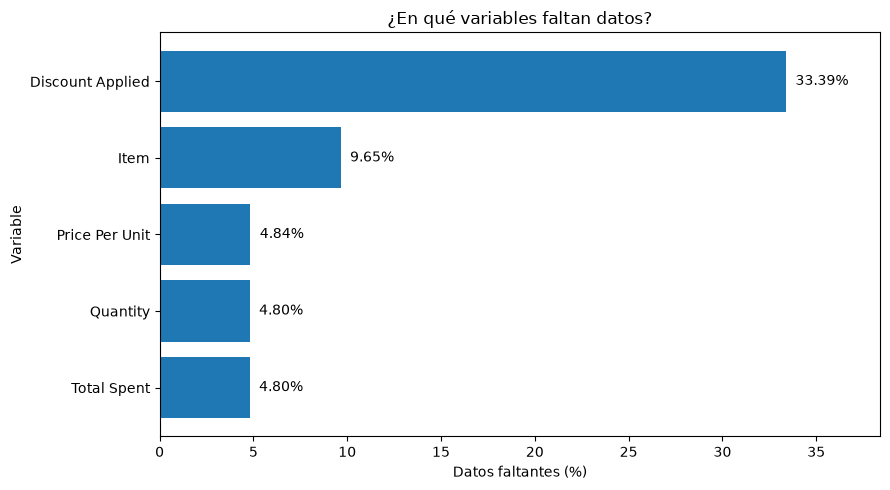

In [8]:
# G01. Datos Faltantes
# ------------------------------------------------------------
datos_g01 = reporte_nulos[reporte_nulos["n_nulos"] > 0].sort_values("pct_nulos")  # Selecciona únicamente variables con faltantes y las ordena

plt.figure(figsize=(9, 5))  # Define el tamaño de la figura
plt.barh(datos_g01.index, datos_g01["pct_nulos"])  # Representa el porcentaje de datos faltantes por variable
plt.xlabel("Datos faltantes (%)")  # Define la etiqueta del eje horizontal
plt.ylabel("Variable")  # Define la etiqueta del eje vertical
plt.title("¿En qué variables faltan datos?")  # Define un título comprensible para público no técnico
plt.xlim(0, datos_g01["pct_nulos"].max() * 1.15)  # Deja espacio para mostrar las etiquetas de porcentaje

for indice, porcentaje in enumerate(datos_g01["pct_nulos"]):
    plt.text(porcentaje + 0.5, indice, f"{porcentaje:.2f}%", va="center")  # Muestra el porcentaje junto a cada barra

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

## **G02. Cardinalidad**

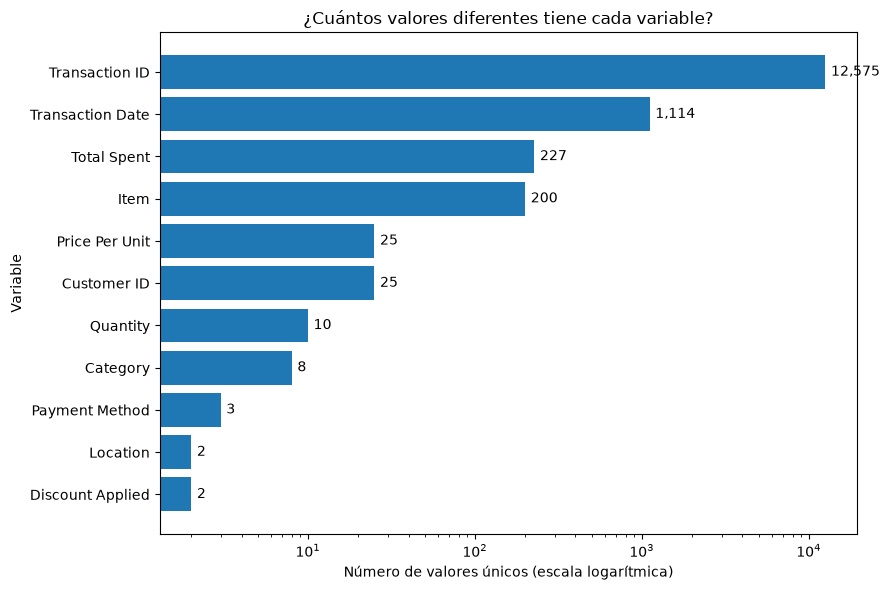

In [9]:
# G02. Cardinalidad
# ------------------------------------------------------------
datos_g02 = cardinalidad.sort_values()  # Ordena las variables según su número de valores únicos

plt.figure(figsize=(9, 6))  # Define el tamaño de la figura
plt.barh(datos_g02.index, datos_g02.values)  # Representa el número de valores únicos por variable
plt.xscale("log")  # Utiliza escala logarítmica para comparar cardinalidades muy diferentes
plt.xlabel("Número de valores únicos (escala logarítmica)")  # Explica explícitamente la escala utilizada
plt.ylabel("Variable")  # Define la etiqueta del eje vertical
plt.title("¿Cuántos valores diferentes tiene cada variable?")  # Define un título comprensible

for indice, valor in enumerate(datos_g02.values):
    plt.text(valor * 1.08, indice, f"{valor:,}", va="center")  # Muestra la cardinalidad real junto a cada barra

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

## **G03. Cantidades**

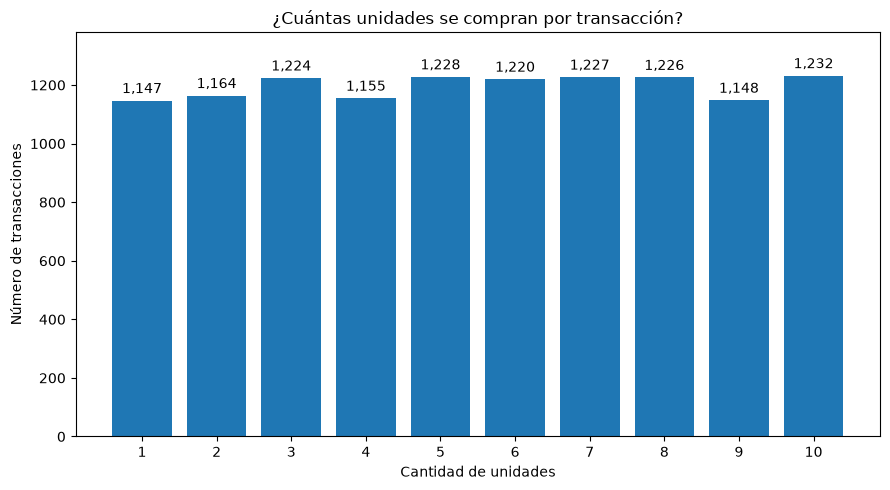

In [10]:
# G03. CANTIDADES
# ------------------------------------------------------------

datos_g03 = df["Quantity"].value_counts(dropna=True).sort_index()  # Cuenta las transacciones para cada cantidad observada

plt.figure(figsize=(9, 5))  # Define el tamaño de la figura
barras_g03 = plt.bar(datos_g03.index, datos_g03.values)  # Representa la frecuencia de cada cantidad

plt.xlabel("Cantidad de unidades")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de transacciones")  # Define la etiqueta del eje vertical
plt.title("¿Cuántas unidades se compran por transacción?")  # Define un título comprensible
plt.xticks(datos_g03.index.astype(int))  # Muestra todos los valores de cantidad observados
plt.bar_label(barras_g03, labels=[f"{valor:,}" for valor in datos_g03.values], padding=3)  # Muestra la frecuencia encima de cada barra
plt.ylim(0, datos_g03.max() * 1.12)  # Deja espacio superior para visualizar las etiquetas

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

## **G04. Precios**

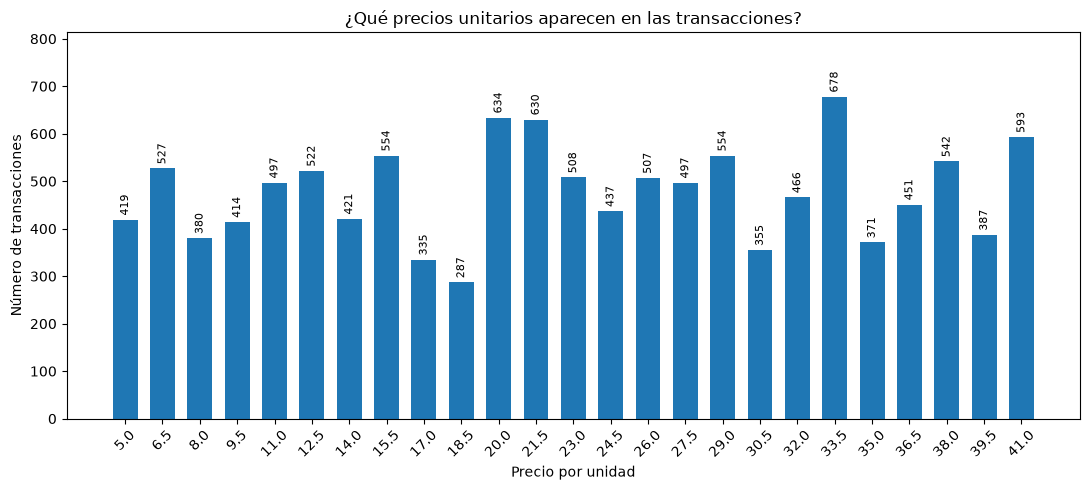

In [11]:
# G04. PRECIOS
# ------------------------------------------------------------

datos_g04 = df["Price Per Unit"].value_counts(dropna=True).sort_index()  # Cuenta las transacciones para cada precio unitario observado

plt.figure(figsize=(11, 5))  # Define el tamaño de la figura
barras_g04 = plt.bar(datos_g04.index, datos_g04.values, width=1.0)  # Representa la frecuencia de cada precio unitario

plt.xlabel("Precio por unidad")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de transacciones")  # Define la etiqueta del eje vertical
plt.title("¿Qué precios unitarios aparecen en las transacciones?")  # Define un título comprensible
plt.xticks(datos_g04.index, rotation=45)  # Muestra los precios observados y mejora su legibilidad
plt.bar_label(barras_g04, labels=[f"{valor:,}" for valor in datos_g04.values], padding=3, fontsize=8, rotation=90)  # Muestra la frecuencia encima de cada barra
plt.ylim(0, datos_g04.max() * 1.20)  # Deja espacio superior para visualizar las etiquetas

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

## **G05. Gasto**

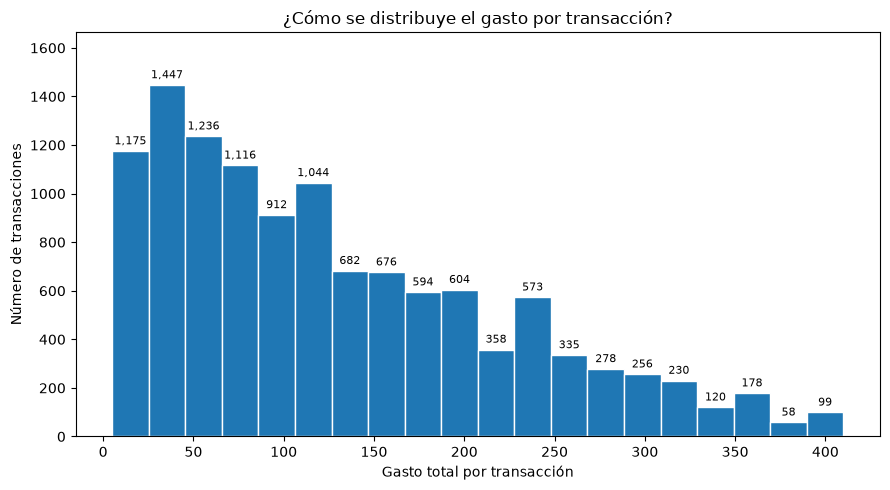

In [12]:
# G05. GASTO
# ------------------------------------------------------------

datos_g05 = df["Total Spent"].dropna()  # Selecciona únicamente los gastos disponibles

plt.figure(figsize=(9, 5))  # Define el tamaño de la figura
frecuencias_g05, intervalos_g05, barras_g05 = plt.hist(datos_g05, bins=20, edgecolor="white")  # Agrupa los gastos en intervalos y conserva sus frecuencias

plt.xlabel("Gasto total por transacción")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de transacciones")  # Define la etiqueta del eje vertical
plt.title("¿Cómo se distribuye el gasto por transacción?")  # Define un título comprensible
plt.bar_label(barras_g05, labels=[f"{int(valor):,}" for valor in frecuencias_g05], padding=3, fontsize=8)  # Muestra la frecuencia encima de cada intervalo
plt.ylim(0, frecuencias_g05.max() * 1.15)  # Deja espacio superior para visualizar las etiquetas

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

# **4. Calidad semántica**


In [13]:
# 4. Calidad semántica
# ------------------------------------------------------------

# La calidad semántica verifica que los valores observados sean coherentes con el significado y dominio esperado de cada variable.

# 04.1. Validación de Quantity
cantidad_valida = df["Quantity"].between(1, 10) | df["Quantity"].isna()  # Verifica que las cantidades observadas estén entre 1 y 10, conservando los faltantes para su análisis posterior

# 04.2. Validación de Price Per Unit
precio_valido = df["Price Per Unit"].between(5, 41) | df["Price Per Unit"].isna()  # Verifica que los precios observados estén entre 5 y 41, conservando los faltantes para su análisis posterior

# 04.3. Validación de Transaction Date
fecha_original = df["Transaction Date"].copy()  # Conserva los valores originales para garantizar trazabilidad
fecha_parseada = pd.to_datetime(df["Transaction Date"], format="%Y-%m-%d", errors="coerce")  # Convierte los textos con formato YYYY-MM-DD a fechas
error_fecha = fecha_original.notna() & fecha_parseada.isna()  # Identifica valores presentes que no cumplen el formato de fecha esperado

## **4.1. Auditoría**

In [14]:
# 4.1. Verificación empírica de dominios numéricos
# ------------------------------------------------------------

print(f"Quantity - mínimo: {df['Quantity'].min()}, máximo: {df['Quantity'].max()}")  # Verifica el rango observado de Quantity
print(f"Price Per Unit - mínimo: {df['Price Per Unit'].min()}, máximo: {df['Price Per Unit'].max()}")  # Verifica el rango observado de Price Per Unit

print("\nValores observados en Quantity:")  # Identifica la distribución de cantidades
display(df["Quantity"].value_counts(dropna=False).sort_index().to_frame(name="frecuencia"))  # Muestra cantidades y frecuencias

print("\nValores observados en Price Per Unit:")  # Identifica los precios existentes
display(df["Price Per Unit"].value_counts(dropna=False).sort_index().to_frame(name="frecuencia"))  # Muestra precios y frecuencias

Quantity - mínimo: 1.0, máximo: 10.0
Price Per Unit - mínimo: 5.0, máximo: 41.0

Valores observados en Quantity:


,frecuencia
Quantity,
1.0,1147
2.0,1164
3.0,1224
4.0,1155
5.0,1228
6.0,1220
7.0,1227
8.0,1226
9.0,1148



Valores observados en Price Per Unit:


,frecuencia
Price Per Unit,
5.0,419
6.5,527
8.0,380
9.5,414
11.0,497
12.5,522
14.0,421
15.5,554
17.0,335


**Conclusions / Conclusiones**

**English**

The semantic validation confirms that Quantity ranges from 1 to 10 and contains exactly 10 observed integer values, with no values outside the expected range. It has 604 missing observations, which should be analyzed separately.

Price Per Unit ranges from 5.0 to 41.0 and contains exactly 25 observed price levels, all within the expected range. It has 609 missing observations.

Therefore, the observed non-missing values of both variables are semantically valid. The remaining issue is missingness rather than invalid numerical values.

---

**Español**

La validación semántica confirma que Quantity varía entre 1 y 10 y contiene exactamente 10 valores enteros observados, sin valores fuera del rango esperado. Presenta 604 observaciones faltantes, que deberán analizarse por separado.

Price Per Unit varía entre 5,0 y 41,0 y contiene exactamente 25 niveles de precio observados, todos dentro del rango esperado. Presenta 609 observaciones faltantes.

Por tanto, los valores no faltantes observados en ambas variables son semánticamente válidos. El problema pendiente corresponde a los datos faltantes y no a valores numéricos inválidos.

# **5. Coherencia de negocio**


In [15]:
# 5. Coherencia de negocio
# ------------------------------------------------------------

# Regla 1: Item -> Category
# Regla 2: Item -> Price Per Unit
# Regla 3: Price Per Unit × Quantity -> Total Spent

# 5.1. Regla 1 Y 2: Coherencia del Catálogo
# ------------------------------------------------------------

coherencia_item = df.dropna(subset=["Item"]).groupby("Item").agg(
    n_categorias=("Category", "nunique"),
    n_precios=("Price Per Unit", "nunique")
).reset_index()  # Cuenta cuántas categorías y precios diferentes tiene asociado cada producto

items_categoria_inconsistente = coherencia_item[coherencia_item["n_categorias"] > 1]  # Detecta productos asociados a más de una categoría
items_precio_inconsistente = coherencia_item[coherencia_item["n_precios"] > 1]  # Detecta productos asociados a más de un precio

# 5.2. Regla 3: Coherencia Aritmética
# ------------------------------------------------------------

df["Total Calculated"] = df["Price Per Unit"] * df["Quantity"]  # Calcula el gasto esperado

datos_completos_total = df[["Price Per Unit", "Quantity", "Total Spent"]].notna().all(axis=1)  # Identifica transacciones evaluables

df["Total Consistent"] = pd.NA  # Inicializa los casos como no evaluables

df.loc[datos_completos_total, "Total Consistent"] = np.isclose(
    df.loc[datos_completos_total, "Total Spent"],
    df.loc[datos_completos_total, "Total Calculated"],
    rtol=1e-9,
    atol=1e-6
)  # Comprueba la coherencia aritmética

## **5.1. Impresión del resumen**

In [16]:
# 5.3. Resultados de coherencia de negocio
# ------------------------------------------------------------
print(f"Items evaluados: {len(coherencia_item):,}")  # Muestra el número de productos evaluados
print(f"Items asociados a más de una categoría: {len(items_categoria_inconsistente):,}")  # Resume inconsistencias Item -> Category
print(f"Items asociados a más de un precio: {len(items_precio_inconsistente):,}")  # Resume inconsistencias Item -> Price Per Unit

print("\nCOHERENCIA DEL GASTO TOTAL")  # Identifica el resultado de la regla aritmética
display(df["Total Consistent"].value_counts(dropna=False).to_frame(name="frecuencia"))  # Muestra transacciones consistentes, inconsistentes y no evaluables

Items evaluados: 200
Items asociados a más de una categoría: 0
Items asociados a más de un precio: 0

COHERENCIA DEL GASTO TOTAL


,frecuencia
Total Consistent,
True,11362
<NA>,1213


## **Consistentes vs Inconsistentes**

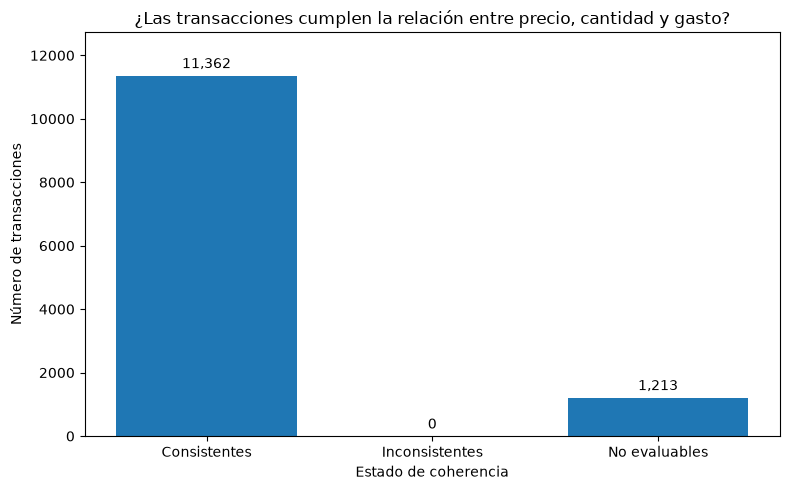

In [17]:
# G06. CONSISTENTES VS INCONSISTENTES
# ------------------------------------------------------------

datos_completos_g06 = df[["Price Per Unit", "Quantity", "Total Spent"]].notna().all(axis=1)  # Identifica las transacciones que tienen disponibles los tres valores necesarios
total_calculado_g06 = df["Price Per Unit"] * df["Quantity"]  # Calcula el gasto esperado según precio por unidad y cantidad
coherencia_g06 = np.isclose(df.loc[datos_completos_g06, "Total Spent"], total_calculado_g06.loc[datos_completos_g06], rtol=1e-9, atol=1e-6)  # Compara el gasto observado con el gasto calculado

datos_g06 = pd.Series({
    "Consistentes": coherencia_g06.sum(),
    "Inconsistentes": (~coherencia_g06).sum(),
    "No evaluables": (~datos_completos_g06).sum()
})  # Resume las transacciones según su estado de coherencia

plt.figure(figsize=(8, 5))  # Define el tamaño de la figura
barras_g06 = plt.bar(datos_g06.index, datos_g06.values)  # Representa el número de transacciones según su estado de coherencia

plt.xlabel("Estado de coherencia")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de transacciones")  # Define la etiqueta del eje vertical
plt.title("¿Las transacciones cumplen la relación entre precio, cantidad y gasto?")  # Define un título comprensible
plt.bar_label(barras_g06, labels=[f"{valor:,}" for valor in datos_g06.values], padding=3)  # Muestra el valor encima de cada barra
plt.ylim(0, datos_g06.max() * 1.12)  # Deja espacio superior para visualizar las etiquetas

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

**Conclusions / Conclusiones**

**English**

Business consistency is strong. All 200 evaluated items are associated with exactly one category and one unit price, validating the relationships Item → Category and Item → Price Per Unit.

For the arithmetic rule, 11,362 transactions are consistent with:

$$ \text{Total Spent}=\text{Price Per Unit}\times\text{Quantity} $$

and no evaluable transaction is inconsistent. The remaining 1,213 transactions are not evaluable because at least one required numerical value is missing. These results support using the three validated business rules to investigate and potentially recover missing data.

---

**Español**

La coherencia de negocio es alta. Los 200 productos evaluados están asociados con una única categoría y un único precio unitario, lo que valida las relaciones Item → Category e Item → Price Per Unit.

Para la regla aritmética, 11.362 transacciones son consistentes con:

$$ \text{Gasto Total}=\text{Precio por Unidad}\times\text{Cantidad} $$

y no se encontraron transacciones evaluables inconsistentes. Las 1.213 transacciones restantes no pueden evaluarse porque falta al menos uno de los valores numéricos necesarios. Estos resultados permiten utilizar las tres reglas de negocio validadas para investigar y potencialmente recuperar datos faltantes.

# **6. Diagnóstico de anomalías**


In [18]:
# 6. Diagnóstico de anomalías
# ------------------------------------------------------------
ESTADOS_ANOMALIA = ["OK", "RECUPERABLE", "AMBIGUO", "INCONSISTENTE", "NO_RECUPERABLE"]  # Define la taxonomía oficial de diagnóstico
df["Estado Anomalia"] = "OK"  # Inicializa todas las transacciones como válidas hasta demostrar la existencia de una anomalía

## **6.1. Patrones de Valores Faltantes**

In [19]:
# 6.1. PATRONES DE VALORES FALTANTES
# ------------------------------------------------------------

variables_diagnostico = ["Item", "Price Per Unit", "Quantity", "Total Spent", "Discount Applied"]  # Define las variables con valores faltantes que requieren diagnóstico
patrones_faltantes = df[variables_diagnostico].isna().value_counts().reset_index(name="frecuencia")  # Identifica las combinaciones reales de valores faltantes
display(patrones_faltantes)  # Muestra los patrones de ausencia observados

,Item,Price Per Unit,Quantity,Total Spent,Discount Applied,frecuencia
0,False,False,False,False,False,7579
1,False,False,False,False,True,3783
2,True,True,False,False,False,404
3,True,False,True,True,False,393
4,True,False,True,True,True,211
5,True,True,False,False,True,205


**Conclusions / Conclusiones**

**English**

The missing-value diagnosis identifies six distinct patterns. Most transactions are either fully complete (7,579) or missing only Discount Applied (3,783).

The remaining 1,213 transactions have missing Item values and follow two important patterns: 609 transactions also lack Price Per Unit, while 604 transactions lack both Quantity and Total Spent. This exactly explains the missing counts previously observed.

Therefore, missingness is structured rather than randomly scattered across variables. The next step is to determine which of these patterns are recoverable using the validated Item → Category, Item → Price Per Unit, and arithmetic business rules.

---

**Español**

El diagnóstico identifica seis patrones distintos de valores faltantes. La mayoría de las transacciones están completamente disponibles (7.579) o presentan únicamente ausencia en Discount Applied (3.783).

Las 1.213 transacciones restantes tienen Item faltante y siguen dos patrones principales: 609 también carecen de Price Per Unit, mientras que 604 carecen simultáneamente de Quantity y Total Spent. Esto explica exactamente los conteos de valores faltantes encontrados anteriormente.

Por tanto, los faltantes presentan una estructura definida y no están dispersos independientemente entre las variables. El siguiente paso será determinar cuáles de estos patrones pueden recuperarse utilizando las reglas validadas Item → Category, Item → Price Per Unit y la relación aritmética del gasto total.

## **6.2. Clasificación del estado de anomalía**

In [20]:
# 6.2. Clasificación del estado de anomalía
# ------------------------------------------------------------

ESTADOS_ANOMALIA = ["OK", "RECUPERABLE", "AMBIGUO", "INCONSISTENTE", "NO_RECUPERABLE"]  # Define la taxonomía oficial de anomalías

df["Estado Anomalia"] = "OK"  # Inicializa todas las transacciones como válidas

faltante_item = df["Item"].isna()  # Identifica transacciones sin producto
faltante_precio = df["Price Per Unit"].isna()  # Identifica transacciones sin precio unitario
faltante_cantidad = df["Quantity"].isna()  # Identifica transacciones sin cantidad
faltante_total = df["Total Spent"].isna()  # Identifica transacciones sin gasto total
faltante_descuento = df["Discount Applied"].isna()  # Identifica transacciones sin información de descuento

df.loc[faltante_descuento & ~faltante_item & ~faltante_precio & ~faltante_cantidad & ~faltante_total, "Estado Anomalia"] = "NO_RECUPERABLE"  # Clasifica los casos donde únicamente falta el descuento

df.loc[faltante_item & ~faltante_precio & ~faltante_cantidad & ~faltante_total, "Estado Anomalia"] = "RECUPERABLE"  # Identifica casos donde Item puede investigarse mediante Category + Price

df.loc[faltante_item & faltante_precio & ~faltante_cantidad & ~faltante_total, "Estado Anomalia"] = "AMBIGUO"  # Clasifica provisionalmente casos sin Item ni precio

df.loc[faltante_item & ~faltante_precio & faltante_cantidad & faltante_total, "Estado Anomalia"] = "RECUPERABLE"  # Identifica casos donde Quantity y Total pueden reconstruirse si Item y precio se recuperan

## **G07. Estado de anomalías**

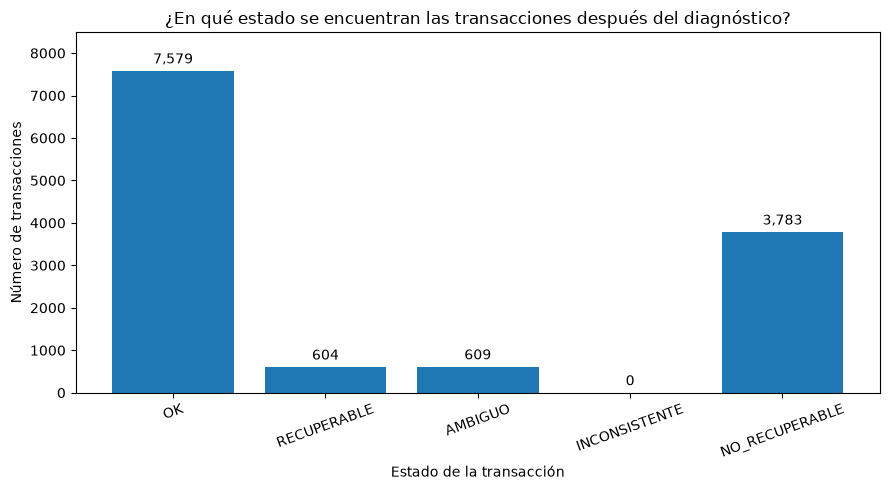

In [21]:
# G07. Estado de anomalías
# ------------------------------------------------------------

datos_g07 = df["Estado Anomalia"].value_counts().reindex(ESTADOS_ANOMALIA, fill_value=0)  # Cuenta las transacciones correspondientes a cada estado de anomalía

plt.figure(figsize=(9, 5))  # Define el tamaño de la figura
barras_g07 = plt.bar(datos_g07.index, datos_g07.values)  # Representa el número de transacciones según su estado

plt.xlabel("Estado de la transacción")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de transacciones")  # Define la etiqueta del eje vertical
plt.title("¿En qué estado se encuentran las transacciones después del diagnóstico?")  # Define un título comprensible
plt.bar_label(barras_g07, labels=[f"{valor:,}" for valor in datos_g07.values], padding=3)  # Muestra el número de transacciones encima de cada barra
plt.ylim(0, datos_g07.max() * 1.12)  # Deja espacio superior para visualizar las etiquetas
plt.xticks(rotation=20)  # Mejora la lectura de los nombres de los estados

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

# **7. Limpieza**


In [22]:
# 7. Limpieza
# ------------------------------------------------------------

df_clean = df.copy(deep=True)  # Crea una copia de trabajo para aplicar las correcciones sin modificar df ni df_raw

columnas_log = ["Transaction ID", "Variable", "Original", "Nuevo", "Acción", "Regla"]  # Define las variables del registro de trazabilidad
log_transformaciones = pd.DataFrame(columns=columnas_log)  # Inicializa el registro de todas las transformaciones realizadas

# Principio metodológico:
# DETECCIÓN -> DIAGNÓSTICO -> DECISIÓN -> CORRECCIÓN

# df_raw   = datos originales e inmutables
# df       = datos utilizados para auditoría y diagnóstico
# df_clean = datos sobre los que se aplicarán las correcciones

## **7.1. Construcción del Catálogo**

In [23]:
# 7.1. Construcción del Catálogo
# ------------------------------------------------------------
catalogo_productos = (
    df_clean
    .dropna(subset=["Item", "Category", "Price Per Unit"])
    [["Item", "Category", "Price Per Unit"]]
    .drop_duplicates()
    .sort_values(["Category", "Item"])
    .reset_index(drop=True)
)  # Construye el catálogo validado Item -> Category -> Price Per Unit

print(f"Productos únicos en el catálogo: {catalogo_productos['Item'].nunique():,}")  # Muestra el número de productos identificados
print(f"Categorías representadas: {catalogo_productos['Category'].nunique():,}")  # Muestra el número de categorías

display(catalogo_productos.head(10))  # Muestra una muestra del catálogo maestro

Productos únicos en el catálogo: 200
Categorías representadas: 8


,Item,Category,Price Per Unit
0,Item_10_BEV,Beverages,18.5
1,Item_11_BEV,Beverages,20.0
2,Item_12_BEV,Beverages,21.5
3,Item_13_BEV,Beverages,23.0
4,Item_14_BEV,Beverages,24.5
5,Item_15_BEV,Beverages,26.0
6,Item_16_BEV,Beverages,27.5
7,Item_17_BEV,Beverages,29.0
8,Item_18_BEV,Beverages,30.5
9,Item_19_BEV,Beverages,32.0


## **7.2. Recuperción del Item**

In [24]:
# 7.2. RECUPERACIÓN DE ITEM
# ------------------------------------------------------------

mapa_item = (
    catalogo_productos
    .groupby(["Category", "Price Per Unit"])
    .agg(
        n_items=("Item", "nunique"),
        Item_recuperado=("Item", "first")
    )
    .reset_index()
)  # Construye las posibles correspondencias Category + Price Per Unit -> Item

mapa_item_unico = mapa_item[mapa_item["n_items"] == 1].copy()  # Conserva únicamente las combinaciones que identifican un solo producto

df_clean = df_clean.merge(
    mapa_item_unico[["Category", "Price Per Unit", "Item_recuperado"]],
    on=["Category", "Price Per Unit"],
    how="left",
    validate="many_to_one"
)  # Incorpora el Item candidato sin modificar todavía los valores originales

mascara_item = df_clean["Item"].isna() & df_clean["Item_recuperado"].notna()  # Identifica los Item faltantes que pueden recuperarse sin ambigüedad

log_item = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_item, "Transaction ID"],
    "Variable": "Item",
    "Original": df_clean.loc[mascara_item, "Item"],
    "Nuevo": df_clean.loc[mascara_item, "Item_recuperado"],
    "Acción": "Recuperación",
    "Regla": "Category + Price Per Unit -> Item"
})  # Registra cada recuperación realizada

log_transformaciones = pd.concat([log_transformaciones, log_item], ignore_index=True)  # Incorpora las recuperaciones al registro de trazabilidad
df_clean.loc[mascara_item, "Item"] = df_clean.loc[mascara_item, "Item_recuperado"]  # Recupera únicamente los Item identificados de forma única
df_clean = df_clean.drop(columns=["Item_recuperado"])  # Elimina la variable auxiliar utilizada durante la recuperación

print(f"Item recuperados: {mascara_item.sum():,}")  # Informa cuántos productos fueron recuperados

Item recuperados: 604


## **Recuperación de price per unit**

In [41]:
# 7.3. RECUPERACIÓN DE PRICE PER UNIT
# ------------------------------------------------------------

mapa_precio = catalogo_productos.set_index("Item")["Price Per Unit"]  # Construye la relación validada Item -> Price Per Unit
precio_recuperado = df_clean["Item"].map(mapa_precio)  # Obtiene el precio esperado para cada producto
mascara_precio = df_clean["Price Per Unit"].isna() & precio_recuperado.notna()  # Identifica precios faltantes que pueden recuperarse mediante Item
log_precio = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_precio, "Transaction ID"],
    "Variable": "Price Per Unit",
    "Original": df_clean.loc[mascara_precio, "Price Per Unit"],
    "Nuevo": precio_recuperado.loc[mascara_precio],
    "Acción": "Recuperación",
    "Regla": "Item -> Price Per Unit"
})  # Registra las recuperaciones de precio

log_transformaciones = pd.concat([log_transformaciones, log_precio], ignore_index=True)  # Incorpora las recuperaciones al registro

df_clean.loc[mascara_precio, "Price Per Unit"] = precio_recuperado.loc[mascara_precio]  # Recupera los precios faltantes

print(f"Price Per Unit recuperados: {mascara_precio.sum():,}")  # Informa cuántos precios fueron recuperados

Price Per Unit recuperados: 0


## **7.4. Recuperación de quantity**

In [25]:
# 7.4. RECUPERACIÓN DE QUANTITY
# ------------------------------------------------------------

cantidad_calculada = df_clean["Total Spent"] / df_clean["Price Per Unit"]  # Calcula la cantidad potencial a partir del gasto y el precio
cantidad_valida_recuperada = cantidad_calculada.notna() & np.isclose(cantidad_calculada, np.round(cantidad_calculada)) & cantidad_calculada.between(1, 10)  # Exige una cantidad entera dentro del dominio validado
mascara_cantidad = df_clean["Quantity"].isna() & cantidad_valida_recuperada  # Identifica cantidades faltantes recuperables

log_cantidad = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_cantidad, "Transaction ID"],
    "Variable": "Quantity",
    "Original": df_clean.loc[mascara_cantidad, "Quantity"],
    "Nuevo": cantidad_calculada.loc[mascara_cantidad].round(),
    "Acción": "Reconstrucción",
    "Regla": "Total Spent / Price Per Unit"
})  # Registra las cantidades reconstruidas

log_transformaciones = pd.concat([log_transformaciones, log_cantidad], ignore_index=True)  # Incorpora las reconstrucciones al registro

df_clean.loc[mascara_cantidad, "Quantity"] = cantidad_calculada.loc[mascara_cantidad].round()  # Recupera las cantidades válidas

print(f"Quantity recuperadas: {mascara_cantidad.sum():,}")  # Informa cuántas cantidades fueron recuperadas

Quantity recuperadas: 0


## **7.5. Recuperación de total spent**

In [ ]:
# 7.5. RECUPERACIÓN DE TOTAL SPENT
# ------------------------------------------------------------

total_recuperado = df_clean["Price Per Unit"] * df_clean["Quantity"]  # Calcula el gasto total esperado

mascara_total = df_clean["Total Spent"].isna() & total_recuperado.notna()  # Identifica gastos faltantes que pueden reconstruirse

log_total = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_total, "Transaction ID"],
    "Variable": "Total Spent",
    "Original": df_clean.loc[mascara_total, "Total Spent"],
    "Nuevo": total_recuperado.loc[mascara_total],
    "Acción": "Reconstrucción",
    "Regla": "Price Per Unit × Quantity"
})  # Registra los gastos reconstruidos

log_transformaciones = pd.concat([log_transformaciones, log_total], ignore_index=True)  # Incorpora las reconstrucciones al registro

df_clean.loc[mascara_total, "Total Spent"] = total_recuperado.loc[mascara_total]  # Recupera los gastos totales

print(f"Total Spent recuperados: {mascara_total.sum():,}")  # Informa cuántos gastos fueron recuperados

Total Spent recuperados: 0


## **7.6. Resumen de transformaciones**

In [27]:
# 7.6. RESUMEN DE TRANSFORMACIONES
# ------------------------------------------------------------

print(f"Transformaciones realizadas: {len(log_transformaciones):,}")  # Muestra el número total de valores modificados

print("\nTRANSFORMACIONES POR VARIABLE")  # Identifica el resumen por variable
display(log_transformaciones["Variable"].value_counts().to_frame(name="n_transformaciones"))  # Resume las transformaciones realizadas

print("\nVALORES FALTANTES RESTANTES")  # Identifica los faltantes posteriores a las recuperaciones
display(df_clean.isna().sum().sort_values(ascending=False).to_frame(name="n_nulos"))  # Muestra los valores faltantes que permanecen

print("\nMUESTRA DEL LOG DE TRANSFORMACIONES")  # Identifica el registro de trazabilidad
display(log_transformaciones.head(10))  # Muestra una muestra de las modificaciones realizadas

Transformaciones realizadas: 604

TRANSFORMACIONES POR VARIABLE


,n_transformaciones
Variable,
Item,604



VALORES FALTANTES RESTANTES


,n_nulos
Discount Applied,4199
Total Calculated,1213
Total Consistent,1213
Price Per Unit,609
Item,609
Quantity,604
Total Spent,604
Category,0
Transaction ID,0
Customer ID,0



MUESTRA DEL LOG DE TRANSFORMACIONES


,Transaction ID,Variable,Original,Nuevo,Acción,Regla
0,TXN_1372952,Item,NaN,Item_20_FUR,Recuperación,Category + Price Per Unit -> Item
1,TXN_1809665,Item,NaN,Item_14_BEV,Recuperación,Category + Price Per Unit -> Item
2,TXN_4206593,Item,NaN,Item_21_FUR,Recuperación,Category + Price Per Unit -> Item
3,TXN_3481599,Item,NaN,Item_24_FUR,Recuperación,Category + Price Per Unit -> Item
4,TXN_1621497,Item,NaN,Item_13_PAT,Recuperación,Category + Price Per Unit -> Item
5,TXN_4532214,Item,NaN,Item_8_PAT,Recuperación,Category + Price Per Unit -> Item
6,TXN_5419965,Item,NaN,Item_11_CEA,Recuperación,Category + Price Per Unit -> Item
7,TXN_8210621,Item,NaN,Item_24_BEV,Recuperación,Category + Price Per Unit -> Item
8,TXN_8586300,Item,NaN,Item_16_CEA,Recuperación,Category + Price Per Unit -> Item
9,TXN_1154680,Item,NaN,Item_21_FUR,Recuperación,Category + Price Per Unit -> Item


## **7.7. Eliminación de variables auxiliares de diagnóstico**

In [29]:
# 7.7. ELIMINACIÓN DE VARIABLES AUXILIARES DE DIAGNÓSTICO
# ------------------------------------------------------------

columnas_auxiliares = ["Total Calculated", "Total Consistent", "Estado Anomalia"]  # Define las variables utilizadas únicamente durante el diagnóstico

df_clean = df_clean.drop(columns=columnas_auxiliares, errors="ignore")  # Elimina las variables auxiliares del dataset destinado a exportación

## **7.8. Diagnóstico de los 609 casos sin item y precio**

In [30]:
# 7.8. DIAGNÓSTICO DE LOS 609 CASOS SIN ITEM Y PRECIO
# ------------------------------------------------------------

casos_sin_item_precio = df_clean[
    df_clean["Item"].isna() &
    df_clean["Price Per Unit"].isna() &
    df_clean["Quantity"].notna() &
    df_clean["Total Spent"].notna()
].copy()  # Selecciona los casos donde faltan Item y precio pero existen cantidad y gasto

casos_sin_item_precio["Precio Calculado"] = casos_sin_item_precio["Total Spent"] / casos_sin_item_precio["Quantity"]  # Reconstruye algebraicamente el precio a partir del gasto y la cantidad

casos_sin_item_precio["Precio Valido"] = casos_sin_item_precio["Precio Calculado"].isin(catalogo_productos["Price Per Unit"])  # Comprueba si el precio calculado pertenece al catálogo validado

print(f"Casos evaluados: {len(casos_sin_item_precio):,}")  # Muestra el número de casos analizados
print(f"Precios recuperables: {casos_sin_item_precio['Precio Valido'].sum():,}")  # Muestra cuántos precios calculados pertenecen al catálogo
print(f"Precios no válidos: {(~casos_sin_item_precio['Precio Valido']).sum():,}")  # Muestra cuántos precios calculados no pertenecen al catálogo

display(casos_sin_item_precio[["Transaction ID", "Category", "Quantity", "Total Spent", "Precio Calculado", "Precio Valido"]].head(10))  # Muestra una muestra del diagnóstico

Casos evaluados: 609
Precios recuperables: 609
Precios no válidos: 0


,Transaction ID,Category,Quantity,Total Spent,Precio Calculado,Precio Valido
5,TXN_7482416,Patisserie,10.0,200.0,20.0,True
11,TXN_5422631,Milk Products,8.0,52.0,6.5,True
17,TXN_9634894,Milk Products,10.0,275.0,27.5,True
21,TXN_8685338,Milk Products,3.0,105.0,35.0,True
32,TXN_1543244,Food,8.0,196.0,24.5,True
127,TXN_4608122,Butchers,10.0,275.0,27.5,True
159,TXN_3822751,Butchers,9.0,126.0,14.0,True
216,TXN_7804271,Patisserie,8.0,40.0,5.0,True
247,TXN_3433195,Electric household essentials,7.0,150.5,21.5,True
271,TXN_7571093,Milk Products,9.0,99.0,11.0,True


## **7.9. Recuperación de price per unit mediante total / quantity**

In [31]:
# 7.9. RECUPERACIÓN DE PRICE PER UNIT MEDIANTE TOTAL / QUANTITY
# ------------------------------------------------------------

precio_calculado = df_clean["Total Spent"] / df_clean["Quantity"]  # Calcula el precio unitario a partir del gasto total y la cantidad
mascara_precio_calculable = df_clean["Price Per Unit"].isna() & precio_calculado.notna() & precio_calculado.isin(catalogo_productos["Price Per Unit"])  # Identifica precios faltantes que pueden recuperarse con un valor válido del catálogo
log_precio_calculado = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_precio_calculable, "Transaction ID"],
    "Variable": "Price Per Unit",
    "Original": df_clean.loc[mascara_precio_calculable, "Price Per Unit"],
    "Nuevo": precio_calculado.loc[mascara_precio_calculable],
    "Acción": "Reconstrucción",
    "Regla": "Total Spent / Quantity"
})  # Registra cada precio unitario reconstruido

log_transformaciones = pd.concat([log_transformaciones, log_precio_calculado], ignore_index=True)  # Incorpora las reconstrucciones al registro de trazabilidad

df_clean.loc[mascara_precio_calculable, "Price Per Unit"] = precio_calculado.loc[mascara_precio_calculable]  # Recupera los precios unitarios faltantes

print(f"Price Per Unit recuperados: {mascara_precio_calculable.sum():,}")  # Informa cuántos precios fueron recuperados

Price Per Unit recuperados: 609


## **7.10. Segunda recuperación de item**

In [32]:
# 7.10. SEGUNDA RECUPERACIÓN DE ITEM
# ------------------------------------------------------------

mapa_item_unico = (
    catalogo_productos
    .groupby(["Category", "Price Per Unit"])
    .agg(
        n_items=("Item", "nunique"),
        Item_recuperado=("Item", "first")
    )
    .reset_index()
)  # Construye nuevamente la relación Category + Price Per Unit -> Item

mapa_item_unico = mapa_item_unico[mapa_item_unico["n_items"] == 1].copy()  # Conserva únicamente las combinaciones que identifican un solo producto

df_clean = df_clean.merge(
    mapa_item_unico[["Category", "Price Per Unit", "Item_recuperado"]],
    on=["Category", "Price Per Unit"],
    how="left",
    validate="many_to_one"
)  # Incorpora el producto candidato a partir de Category y Price Per Unit

mascara_item_segunda = df_clean["Item"].isna() & df_clean["Item_recuperado"].notna()  # Identifica los Item todavía faltantes que ahora pueden recuperarse

log_item_segunda = pd.DataFrame({
    "Transaction ID": df_clean.loc[mascara_item_segunda, "Transaction ID"],
    "Variable": "Item",
    "Original": df_clean.loc[mascara_item_segunda, "Item"],
    "Nuevo": df_clean.loc[mascara_item_segunda, "Item_recuperado"],
    "Acción": "Recuperación",
    "Regla": "Category + Price Per Unit -> Item"
})  # Registra cada producto recuperado

log_transformaciones = pd.concat([log_transformaciones, log_item_segunda], ignore_index=True)  # Incorpora las nuevas recuperaciones al registro

df_clean.loc[mascara_item_segunda, "Item"] = df_clean.loc[mascara_item_segunda, "Item_recuperado"]  # Recupera los Item identificados sin ambigüedad

df_clean = df_clean.drop(columns=["Item_recuperado"])  # Elimina la variable auxiliar

print(f"Item adicionales recuperados: {mascara_item_segunda.sum():,}")  # Informa cuántos Item adicionales fueron recuperados

Item adicionales recuperados: 609


## **7.11. Resultado final de la recuperación**

In [33]:
# 7.11. RESULTADO FINAL DE LA RECUPERACIÓN
# ------------------------------------------------------------

print(f"Transformaciones totales realizadas: {len(log_transformaciones):,}")  # Muestra el número total de modificaciones realizadas

print("\nTRANSFORMACIONES POR VARIABLE")  # Identifica el resumen de transformaciones
display(log_transformaciones["Variable"].value_counts().to_frame(name="n_transformaciones"))  # Cuenta las modificaciones realizadas por variable

print("\nVALORES FALTANTES RESTANTES")  # Identifica los valores que no pudieron recuperarse
display(df_clean.isna().sum().sort_values(ascending=False).to_frame(name="n_nulos"))  # Muestra los valores faltantes restantes

Transformaciones totales realizadas: 1,822

TRANSFORMACIONES POR VARIABLE


,n_transformaciones
Variable,
Item,1213
Price Per Unit,609



VALORES FALTANTES RESTANTES


,n_nulos
Discount Applied,4199
Total Spent,604
Quantity,604
Category,0
Customer ID,0
Transaction ID,0
Price Per Unit,0
Item,0
Payment Method,0
Location,0


## **7.12. Auditoría final de valores faltantes**

In [ ]:
# 7.12. AUDITORÍA FINAL DE VALORES FALTANTES
# ------------------------------------------------------------

columnas_originales = df_raw.columns.tolist()  # Recupera únicamente las variables pertenecientes al dataset original

faltantes_finales = pd.DataFrame({
    "Antes": df[columnas_originales].isna().sum(),
    "Después": df_clean[columnas_originales].isna().sum()
})  # Compara los faltantes originales con los faltantes posteriores a la limpieza

faltantes_finales["Recuperados"] = faltantes_finales["Antes"] - faltantes_finales["Después"]  # Calcula el número de valores recuperados
faltantes_finales["Recuperación (%)"] = np.where(faltantes_finales["Antes"] > 0, (faltantes_finales["Recuperados"] / faltantes_finales["Antes"] * 100).round(2), 0)  # Calcula el porcentaje recuperado

display(faltantes_finales[faltantes_finales["Antes"] > 0])  # Muestra únicamente las variables que originalmente tenían valores faltantes

,Antes,Después,Recuperados,Recuperación (%)
Item,1213,0,1213,100.0
Price Per Unit,609,0,609,100.0
Quantity,604,604,0,0.0
Total Spent,604,604,0,0.0
Discount Applied,4199,4199,0,0.0


**Conclusions / Conclusiones**

**English**

The cleaning process deterministically recovered all missing Item and Price Per Unit values, resulting in 1,822 traceable transformations. Missing values remain in Quantity, Total Spent, and Discount Applied because the available information does not support their unique reconstruction. These values are therefore preserved as missing rather than imputed arbitrarily.

---

**Español**

El proceso de limpieza recuperó de forma determinística todos los valores faltantes de Item y Price Per Unit, para un total de 1.822 transformaciones trazables. Los faltantes de Quantity, Total Spent y Discount Applied permanecen porque la información disponible no permite reconstruirlos de manera única. Por esta razón, se conservan como faltantes en lugar de realizar imputaciones arbitrarias.

## **G08. Antes vs después de la limpieza**

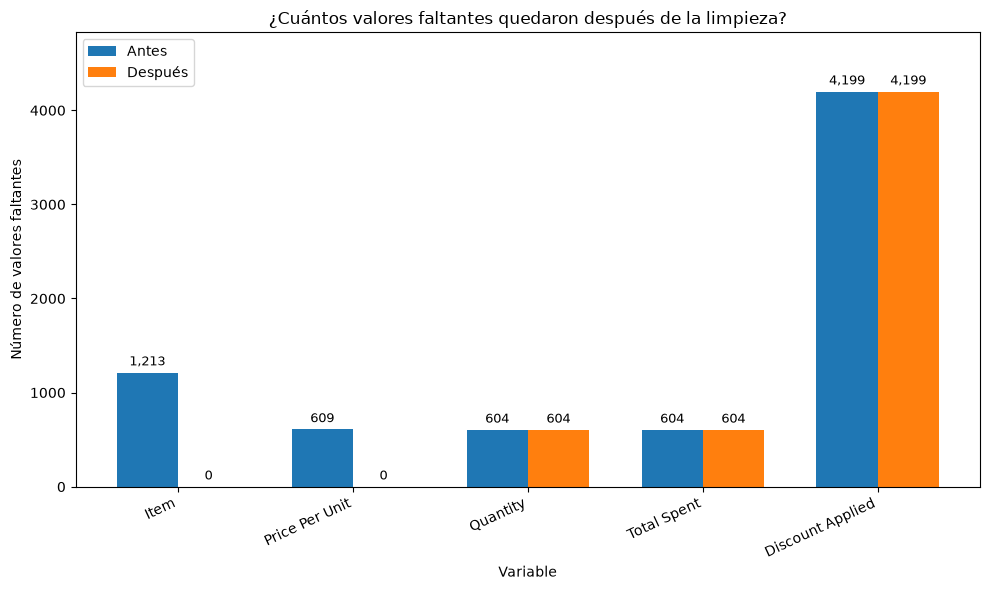

In [35]:
# G08. ANTES VS DESPUÉS DE LA LIMPIEZA
# ------------------------------------------------------------

datos_g08 = faltantes_finales[faltantes_finales["Antes"] > 0][["Antes", "Después"]].copy()  # Selecciona únicamente las variables que originalmente tenían valores faltantes

posiciones_g08 = np.arange(len(datos_g08))  # Define la posición de cada variable en el eje horizontal
ancho_g08 = 0.35  # Define el ancho de cada barra

plt.figure(figsize=(10, 6))  # Define el tamaño de la figura

barras_antes_g08 = plt.bar(posiciones_g08 - ancho_g08 / 2, datos_g08["Antes"], width=ancho_g08, label="Antes")  # Representa los valores faltantes antes de la limpieza
barras_despues_g08 = plt.bar(posiciones_g08 + ancho_g08 / 2, datos_g08["Después"], width=ancho_g08, label="Después")  # Representa los valores faltantes después de la limpieza

plt.xlabel("Variable")  # Define la etiqueta del eje horizontal
plt.ylabel("Número de valores faltantes")  # Define la etiqueta del eje vertical
plt.title("¿Cuántos valores faltantes quedaron después de la limpieza?")  # Define un título comprensible
plt.xticks(posiciones_g08, datos_g08.index, rotation=25, ha="right")  # Muestra los nombres de las variables
plt.bar_label(barras_antes_g08, labels=[f"{valor:,}" for valor in datos_g08["Antes"]], padding=3, fontsize=9)  # Muestra los valores originales encima de las barras
plt.bar_label(barras_despues_g08, labels=[f"{valor:,}" for valor in datos_g08["Después"]], padding=3, fontsize=9)  # Muestra los valores posteriores encima de las barras
plt.ylim(0, datos_g08[["Antes", "Después"]].to_numpy().max() * 1.15)  # Deja espacio superior para visualizar las etiquetas
plt.legend()  # Identifica las barras correspondientes al antes y después

plt.tight_layout()  # Ajusta automáticamente los elementos de la figura
plt.show()  # Muestra la figura

**Conclusions / Conclusiones**

**English**

The cleaning process fully recovered the missing values in Item (1,213 → 0) and Price Per Unit (609 → 0), resulting in 1,822 traceable transformations. Missing values in Quantity, Total Spent, and Discount Applied were preserved because they could not be deterministically reconstructed.

---

**Español**

El proceso de limpieza recuperó completamente los valores faltantes de Item (1.213 → 0) y Price Per Unit (609 → 0), para un total de 1.822 transformaciones trazables. Los faltantes de Quantity, Total Spent y Discount Applied se conservaron porque no podían reconstruirse de forma determinística.

Con esto, G08 puede darse por terminado. El siguiente bloque corresponde a 08. Validación post-limpieza, donde debemos comprobar que las 1.822 recuperaciones no introdujeron incoherencias en Item → Category, Item → Price Per Unit ni en Price × Quantity = Total.

## **7.13. Exportación para imputación estadística en R**

In [ ]:
# Importar PyArrow para exportar el dataset a Parquet, asegurando que se preserve la estructura y los tipos de datos originales.

import pyarrow as pa  # Importa PyArrow desde el entorno virtual activo
print(f"PyArrow: {pa.__version__}")  # Comprueba la versión instalada

# 7.13. EXPORTACIÓN PARA IMPUTACIÓN ESTADÍSTICA EN R
# ------------------------------------------------------------

RUTA_PRE_IMPUTACION_PARQUET = RUTA_PROCESSED / "retail_sales_pre_imputation.parquet"  # Define la ruta del archivo Parquet previo a la imputación
RUTA_PRE_IMPUTACION_CSV = RUTA_PROCESSED / "retail_sales_pre_imputation.csv"  # Define la ruta CSV como formato de respaldo

columnas_auxiliares = ["Total Calculated", "Total Consistent", "Estado Anomalia"]  # Define las variables auxiliares utilizadas durante el diagnóstico

df_pre_imputacion = df_clean.drop(columns=columnas_auxiliares, errors="ignore").copy(deep=True)  # Crea el dataset que será utilizado para la imputación estadística

df_pre_imputacion.to_parquet(RUTA_PRE_IMPUTACION_PARQUET, index=False)  # Exporta el dataset a Parquet preservando los tipos de datos
df_pre_imputacion.to_csv(RUTA_PRE_IMPUTACION_CSV, index=False)  # Exporta una copia adicional en formato CSV

print(f"Dimensiones exportadas: {df_pre_imputacion.shape[0]:,} filas × {df_pre_imputacion.shape[1]:,} columnas")  # Verifica las dimensiones del dataset exportado
print(f"Parquet: {RUTA_PRE_IMPUTACION_PARQUET.resolve()}")  # Muestra la ubicación del archivo Parquet
print(f"CSV: {RUTA_PRE_IMPUTACION_CSV.resolve()}")  # Muestra la ubicación del archivo CSV

PyArrow: 25.0.1
Dimensiones exportadas: 12,575 filas × 11 columnas
Parquet: D:\Proyectos_IA\0_Retail_Store_Sales_Dirty_for_Data_Cleaning\data\processed\retail_sales_pre_imputation.parquet
CSV: D:\Proyectos_IA\0_Retail_Store_Sales_Dirty_for_Data_Cleaning\data\processed\retail_sales_pre_imputation.csv


**Conclusions / Conclusiones**

**English**

The deterministic cleaning stage successfully recovered all missing values in `Item` (1,213) and `Price Per Unit` (609), resulting in **1,822 traceable transformations** without using arbitrary statistical imputation.

After this process, missing values remain in `Quantity` (604), `Total Spent` (604), and `Discount Applied` (4,199). The 604 missing values in `Quantity` and `Total Spent` occur simultaneously, so the relationship `Total Spent = Price Per Unit × Quantity` is insufficient to reconstruct them uniquely. Likewise, the available business rules do not provide enough information to determine the missing values of `Discount Applied`.

For this reason, the remaining missing values will be addressed in a separate **statistical imputation stage using R**. R is selected because its statistical ecosystem, particularly packages such as `mice`, provides a mature framework for implementing and comparing multiple imputation methods, including predictive mean matching (PMM), CART, Random Forest, and logistic regression for binary variables.

The original variables will be preserved. Each imputation method will generate a new variable, allowing the alternatives to be evaluated before selecting a final method. This maintains a clear distinction between **deterministically recovered values** and **statistically estimated values**.

---

**Español**

La etapa de limpieza determinística permitió recuperar todos los valores faltantes de `Item` (1.213) y `Price Per Unit` (609), para un total de **1.822 transformaciones trazables**, sin recurrir a imputaciones estadísticas arbitrarias.

Después de este proceso permanecen valores faltantes en `Quantity` (604), `Total Spent` (604) y `Discount Applied` (4.199). Los 604 faltantes de `Quantity` y `Total Spent` aparecen simultáneamente, por lo que la relación `Total Spent = Price Per Unit × Quantity` no permite reconstruirlos de manera única. Asimismo, las reglas de negocio disponibles no proporcionan información suficiente para determinar los valores faltantes de `Discount Applied`.

Por esta razón, los valores faltantes restantes serán tratados en una etapa independiente de **imputación estadística utilizando R**. Se selecciona R por su ecosistema especializado en análisis estadístico y, particularmente, por herramientas como `mice`, que permiten implementar y comparar diferentes métodos de imputación, entre ellos Predictive Mean Matching (PMM), CART, Random Forest y regresión logística para variables binarias.

Las variables originales serán conservadas. Cada método de imputación generará una nueva variable, lo que permitirá comparar los resultados antes de seleccionar el método definitivo. De esta manera se mantiene una separación metodológica entre los valores **recuperados mediante reglas determinísticas** y los valores **estimados mediante imputación estadística**.